# 1. Upload data 
* Data was downloaded from GEMStat Database in five batches due to download size constraints imposed by GEMStat.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

pd.set_option('display.max_columns', 50)

In [2]:
df_1 = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Capstone/Armeria_CortanAchute_Data1/samples_1.csv', sep=';', low_memory=False)

In [3]:
df_2 = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Capstone/Colorado_Hondo_Data2/samples_2.csv', sep=';', low_memory=False)

In [4]:
df_3 = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Capstone/Panuco_Papaloadan_Data3/samples_3.csv', sep=';', low_memory=False)

In [5]:
df_4 = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Capstone/RioGrande_SantaClara_Data4/samples_4.csv', sep=';', low_memory=False)

In [6]:
df_5 = pd.read_csv('/Users/rue/Desktop/Berkeley Extension/Capstone/Suchiate_Yaqui_Data5/samples_5.csv', sep=';', low_memory=False)

# 2. Combine five datasets into one dataframe

* Row concatenation for the five dataframes yielded a singular dataframe with shape (1222396, 11).
* Rows with Poor or Suspect values in 'Data Quality' column were dropped based on GEMStat rating of weak plausbilty.
* Parameter codes with more than one corresponding unit were identified. Turbidity was the only parameter using more than 1 unit and had 50783 turbidity samples measured in NTU and 137 turbidity samples measured in JCU. Since the 137 JCU samples represent 0.27% of the dataset, they were dropped.
* The resulting shape is (1135919, 11).

In [7]:
df_1.head(2)

,GEMS Station Number,Sample Date,Sample Time,Depth,Parameter Code,Analysis Method Code,Value Flags,Value,Unit,Data Quality,Status
0,MEX00006,1990-01-30,12:00,0.0,TP,COL-SnCl-SA-PPS,NaN,0.085,mg/l,Fair,NaN
1,MEX00006,1990-01-30,12:00,0.0,pH,pH-POT-25,NaN,7.700,---,Fair,NaN


In [8]:
df_1.columns

Index(['GEMS Station Number', 'Sample Date', 'Sample Time', 'Depth',
       'Parameter Code', 'Analysis Method Code', 'Value Flags', 'Value',
       'Unit', 'Data Quality', 'Status'],
      dtype='str')

In [9]:
# Check shapes of each df. Total rows of 5 df: 
list_df = [df_1, df_2, df_3, df_4, df_5]
rows = 0
for df in list_df:
    print(df.shape)
    rows = rows + df.shape[0]
print("Total rows:", rows)

(338992, 11)
(82659, 11)
(295389, 11)
(249884, 11)
(255472, 11)
Total rows: 1222396


In [10]:
# Concatenate rows one on top of each other
df = pd.concat(list_df, axis = 0).reset_index(drop = True)

In [11]:
# Confirm correct concatenation
df.shape

(1222396, 11)

In [12]:
# Drop rows with Poor or Suspect Data Quality
df.drop(df[df['Data Quality'].isin(['Suspect', 'Poor'])].index, inplace=True)

In [13]:
# Make sure units are consistent
df.groupby('Parameter Code')['Unit'].unique()

Parameter Code
BOD              [mg/l]
COD              [mg/l]
EC              [µS/cm]
ECOLI        [1/100 ml]
FECALCOLI    [1/100 ml]
NH3N             [mg/l]
NO2N             [mg/l]
NO3N             [mg/l]
O2-Dis           [mg/l]
TDS              [mg/l]
TEMP               [°C]
TKN              [mg/l]
TN               [mg/l]
TOC              [mg/l]
TON              [mg/l]
TP               [mg/l]
TRP              [mg/l]
TSS              [mg/l]
TURB         [JCU, NTU]
pH                [---]
Name: Unit, dtype: object

In [14]:
# Turbidity uses two units. Investigate!
df[df['Parameter Code'] == 'TURB']['Unit'].value_counts()

Unit
NTU    50783
JCU      137
Name: count, dtype: int64

In [15]:
# Since rows with TURB measurements in JCU are low, drop them.
df.drop(df[(df['Parameter Code'] == 'TURB') & (df['Unit'] == 'JCU')].index, inplace=True)

In [16]:
# Check
df[df['Parameter Code'] == 'TURB']['Unit'].value_counts()

Unit
NTU    50783
Name: count, dtype: int64

In [17]:
df.shape

(1135919, 11)

# 3. Rearrange DataFrame
* Reshaped the dataset so each row represents a unique sampling event(station, date, time, and depth), with each water-quality parameter stored in its own column.
* Calculated the mean value when multiple measurements existed for the same parameter and sampling event.
* Reset the index and removed the columns axis name for cleaner output.
* Rows without the target feature ECOLI were dropped.
* Resulting dataframe has the shape (46467,24).

In [18]:
df_pivot = df.pivot_table(
    index=['GEMS Station Number', 'Sample Date', 'Sample Time', 'Depth'],
    columns='Parameter Code',
    values='Value',
    aggfunc='mean'
).reset_index()

df_pivot.columns.name = None

In [19]:
df_pivot.head(5)

,GEMS Station Number,Sample Date,Sample Time,Depth,BOD,COD,EC,ECOLI,FECALCOLI,NH3N,NO2N,NO3N,O2-Dis,TDS,TEMP,TKN,TN,TOC,TON,TP,TRP,TSS,TURB,pH
0,GTM00080,2004-01-15,12:00,1.0,NaN,NaN,152.0,NaN,NaN,NaN,0.078,2.7,6.5,111.0,23.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.81,7.70
1,GTM00080,2004-02-15,12:00,1.0,NaN,13.0,159.0,NaN,NaN,NaN,0.022,2.7,5.5,116.0,25.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.17,7.75
2,GTM00080,2004-03-15,12:00,1.0,NaN,10.9,169.0,NaN,NaN,NaN,NaN,2.4,4.9,124.0,26.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.91,7.88
3,GTM00080,2004-04-15,12:00,1.0,NaN,21.4,153.0,NaN,NaN,NaN,0.031,4.9,4.7,112.0,25.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,48.20,7.73
4,GTM00080,2004-05-15,12:00,1.0,NaN,53.6,146.0,NaN,NaN,NaN,NaN,2.0,5.1,106.0,24.7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.70,7.69


In [20]:
# remove rows without target feature: ECOLI
df_pivot = df_pivot.dropna(
    subset=['ECOLI']
).reset_index()

# 4. EDA
* The dataset consists of 22 numeric columns (21 after the index column is dropped) and 3 string columns (station number, sample date, sample time), with 46,467 sampling events.
* Missing values are present in every water-quality column except Depth and ECOLI. They range from 239 (FECALCOLI) to 6,491 (TKN), or 0.51% to 13.97% of rows, so no column is missing enough data to drop.
* For most parameters, the mean is much larger than the median (for example, ECOLI has a mean of about 23,710 vs. a median of 256, and NH3N has a mean of 2.89 vs. a median of 0.14). This indicates right-skewed distributions driven by a smaller number of extreme values.
* Histograms of BOD, COD, TN, and TP show a long right tail, so scaling that is robust to outliers is appropriate.
* Depth is nearly constant: the 25th, 50th, and 75th percentiles are all 0.3 m, although values range from 0.15 to 7.52 m.
* ECOLI and FECALCOLI show a strong positive relationship, which is expected since E. coli is a subset of fecal coliforms. This motivates comparing models with and without FECALCOLI.
* ECOLI is highly concentrated at the upper end: the 90th and 95th percentiles are both 24,000, and the maximum is 24,196,000. The ten largest values are all identical (24,196,000) and look like a reporting limit rather than true measurements, so they were kept.

In [21]:
df_pivot.info()

<class 'pandas.DataFrame'>
RangeIndex: 46467 entries, 0 to 46466
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                46467 non-null  int64  
 1   GEMS Station Number  46467 non-null  str    
 2   Sample Date          46467 non-null  str    
 3   Sample Time          46467 non-null  str    
 4   Depth                46467 non-null  float64
 5   BOD                  45890 non-null  float64
 6   COD                  45348 non-null  float64
 7   EC                   46043 non-null  float64
 8   ECOLI                46467 non-null  float64
 9   FECALCOLI            46228 non-null  float64
 10  NH3N                 45751 non-null  float64
 11  NO2N                 46003 non-null  float64
 12  NO3N                 45897 non-null  float64
 13  O2-Dis               44477 non-null  float64
 14  TDS                  46051 non-null  float64
 15  TEMP                 46096 non-null  float64
 1

In [22]:
df_pivot.describe()

,index,Depth,BOD,COD,EC,ECOLI,FECALCOLI,NH3N,NO2N,NO3N,O2-Dis,TDS,TEMP,TKN,TN,TOC,TON,TP,TRP,TSS,TURB,pH
count,46467.000000,46467.000000,45890.000000,45348.000000,46043.000000,4.646700e+04,4.622800e+04,45751.000000,46003.000000,45897.000000,44477.000000,46051.000000,46096.000000,39976.000000,45181.000000,45565.000000,45808.000000,45862.000000,45615.000000,46085.000000,46044.000000,45483.000000
mean,59338.041621,0.327752,19.294810,65.225876,1057.312154,2.371018e+04,2.891217e+04,2.892247,0.110347,1.054105,5.847273,705.321386,24.658473,1.412210,6.102840,11.672979,2.283891,1.107084,0.739656,113.735757,76.555971,7.826583
std,32989.007842,0.086054,57.689633,116.839579,2174.548152,5.426786e+05,5.892971e+05,9.103807,0.485554,3.136869,2.479978,1553.483549,4.776764,2.626740,12.229492,37.544427,6.340456,2.976128,2.633456,576.867710,432.740965,0.523392
min,1436.000000,0.150000,1.000000,0.970000,3.820000,1.000000e+00,1.000000e+00,0.003000,0.000500,0.000430,0.050000,2.444800,4.000000,0.003000,0.006700,0.060000,0.000000,0.001000,0.000500,0.100000,0.019000,3.800000
25%,30394.500000,0.300000,2.000000,11.900000,302.000000,3.000000e+01,1.500000e+02,0.056000,0.005000,0.081000,4.300000,193.280000,21.200000,0.328000,0.720400,1.920000,0.206000,0.052144,0.012000,10.000000,2.500000,7.500000
50%,54261.000000,0.300000,3.300000,26.620000,592.000000,2.560000e+02,1.789000e+03,0.140000,0.008470,0.313300,6.030000,378.880000,25.200000,0.624441,1.401000,3.890000,0.514505,0.144773,0.058000,20.000000,8.400000,7.800000
75%,84625.500000,0.300000,10.200000,57.012500,1196.850000,4.600000e+03,2.400000e+04,0.720000,0.037900,0.844000,7.400000,766.080000,28.300000,1.329254,4.711003,8.320000,1.282745,0.793975,0.362050,59.000000,32.600000,8.200000
max,126100.000000,7.520000,985.000000,1000.000000,99770.000000,2.419600e+07,2.419600e+07,414.400000,20.316800,111.546160,86.000000,43128.000000,48.200000,77.901500,99.811000,2407.000000,98.828000,67.380000,92.950000,39780.000000,19900.000000,10.500000


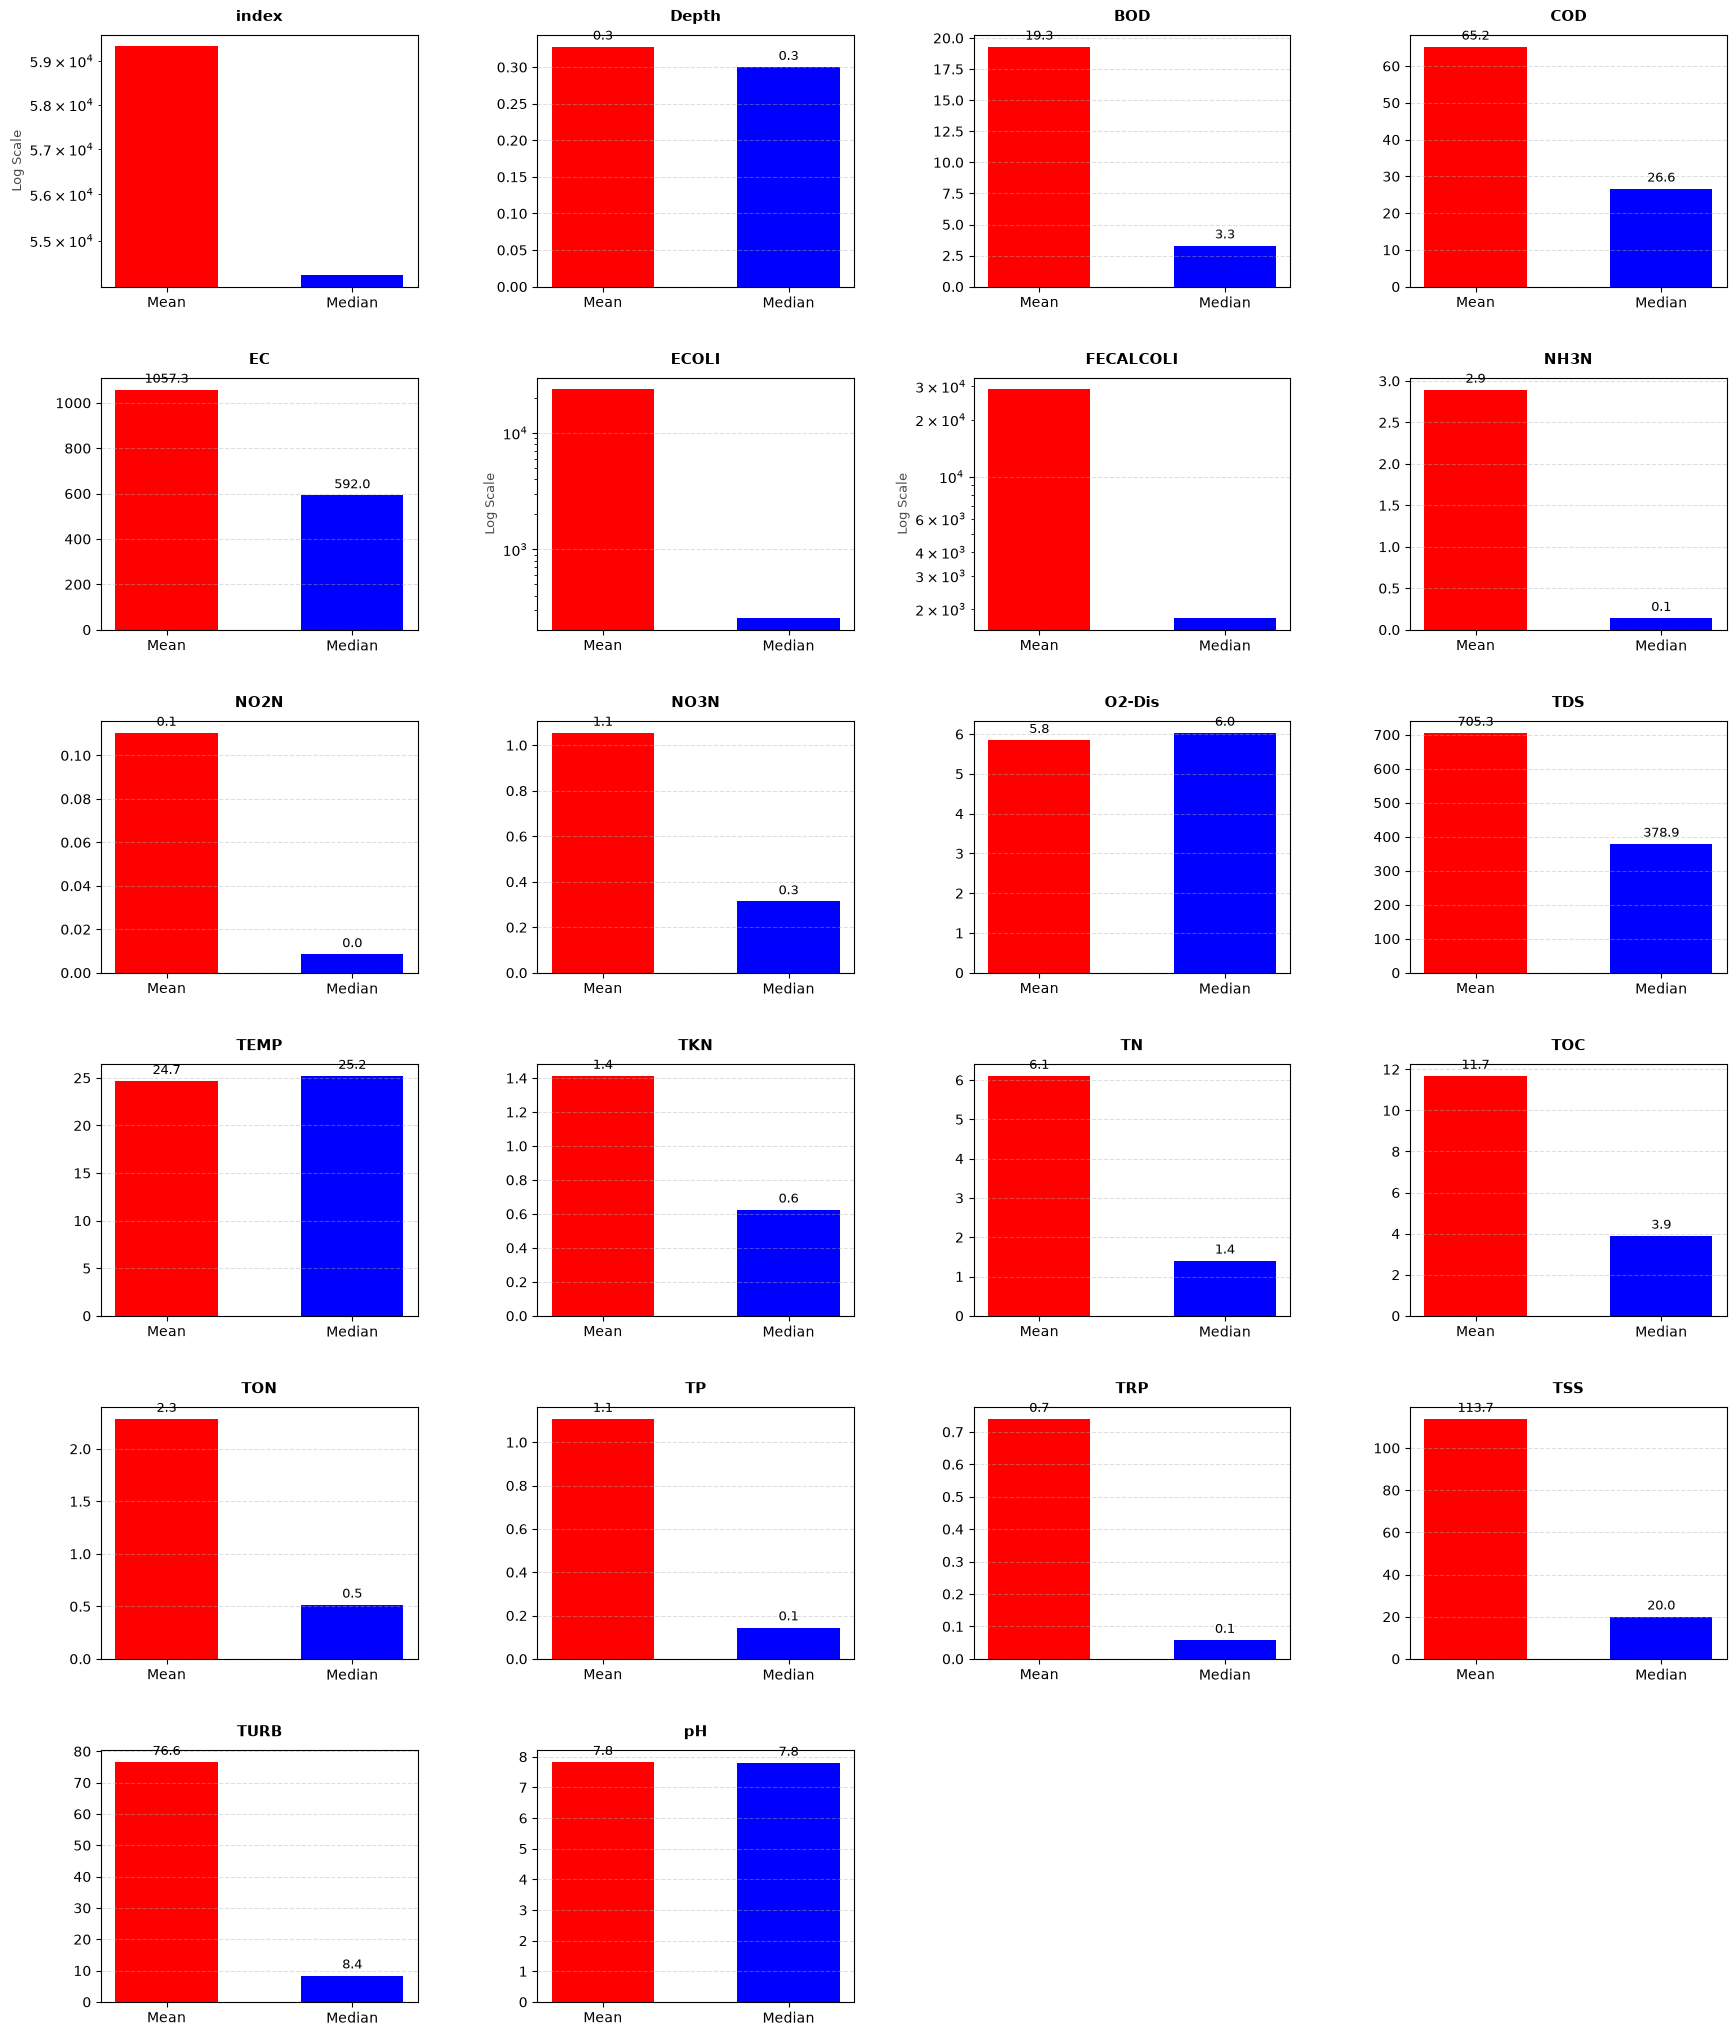

In [23]:
# Mean vs. Median Comparisons

# 1. Extract statistical metrics 
stats = df_pivot.describe().loc[['mean', '50%']]
features = stats.columns
num_features = len(features)

# 2. Structure a clean layout grid (4 columns wide)
num_cols = 4
num_rows = int(np.ceil(num_features / num_cols))  # Will calculate 6 rows for 22 columns

# 3. Initialize the grid figure canvas
fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 3.5 * num_rows))
axes = axes.flatten()  # Safely flattens the grid into a single-index array

# 4. Generate individual plots for all 22 features
for i, col in enumerate(features):
    ax = axes[i]
    values = [stats.loc['mean', col], stats.loc['50%', col]]
    labels = ['Mean', 'Median']
    
    # Make the mean bars red and the medium bars blue
    bars = ax.bar(labels, values, color=['red', 'blue'], width=0.55)
    
    # Title the subplot with the feature name
    ax.set_title(col, fontsize=11, fontweight='bold', pad=10)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    # Handle features with large scales (like ECOLI)
    max_val = max(values)
    if max_val > 10000:
        ax.set_yscale('log')  # Uses a log scale only if values scale aggressively
        ax.set_ylabel('Log Scale', fontsize=9, alpha=0.7)
    else:
        # Standard value formatting for reasonable numbers
        ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)

# 5. Clean up the grid by deleting the 2 empty mathematical spaces (24 slots - 22 features)
for j in range(num_features, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(pad=3.0)  # Adds clean structural padding between subplots
plt.show()

### Mean vs. Median Comparisons
The vast majority of water quality parameters show a Mean that is vastly larger than the Median, indicating non-normal distribution across the dataset. The low Median values prove that the water body maintains a relatively clean baseline concentration most of the time, while the elevated Means are driven upwards by extreme, intermittent pollution events. Parameters like Turbidity (Mean: 76.6 NTU vs. Median: 8.4 NTU) and TSS (Mean: 113.7 vs. Median: 20.0) highlight sudden environmental shock events, such as heavy stormwater runoff or discharge events. Only a few parameters, specifically pH, Temperature, and Dissolved Oxygen, show an identical Mean and Median, indicating they follow stable, predictable baseline balances. Since the values include significant outliers, standard linear machine learning models will suffer from severe bias. 

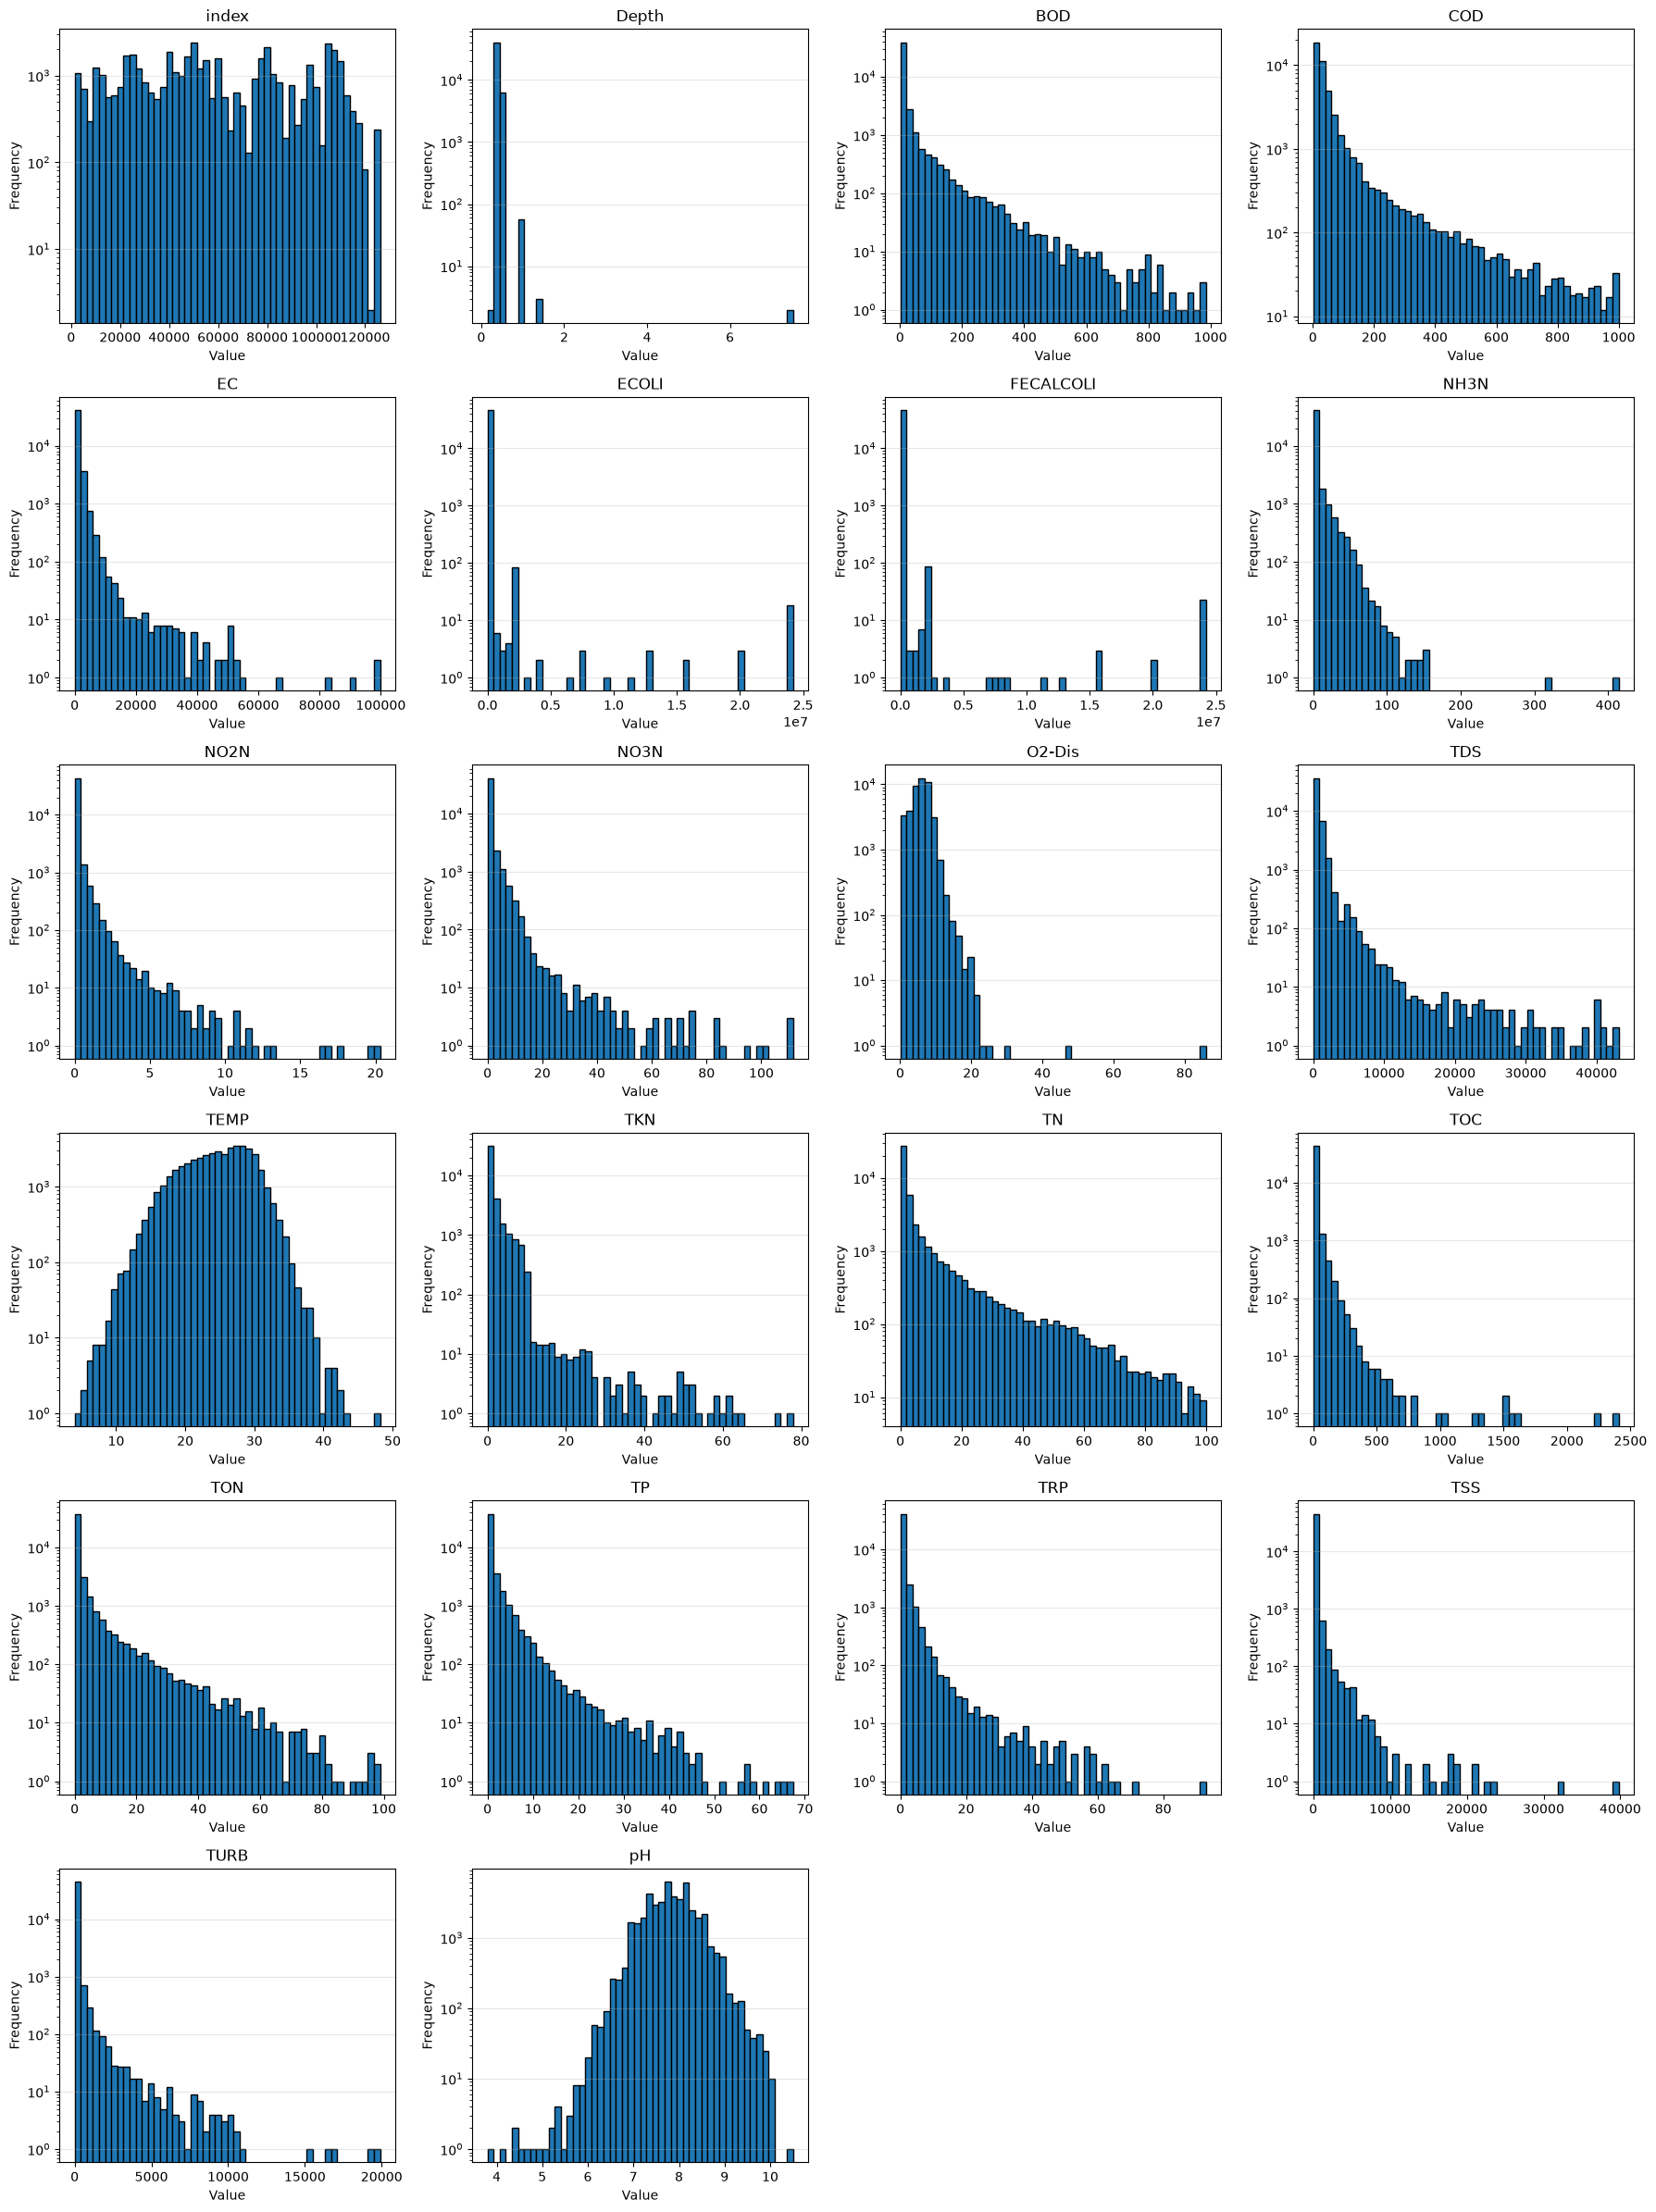

In [24]:
# Histogram Distributions

features = df_pivot.select_dtypes(include='number').columns
num_cols = 4
num_rows = int(np.ceil(len(features) / num_cols))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 4 * num_rows))
axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]
    ax.set_yscale('log')
    data = df_pivot[col].dropna()

    ax.hist(data, bins=50, edgecolor='black')
    ax.set_title(col)
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')
    ax.grid(axis='y', alpha=0.3)

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### ^ Histogram Distributions
Several histograms such as BOD, COD, TN, and TP undergo exponential decay indicated by a downward slope that extends into a tail on the right. This means their frequencies drop off exponentially as concentrations rise. Temperature and pH follow Gaussian distributions indicated by the bell curve shaped of their histograms. This confirms the sample sites are water and establishes a chemical baseline. Biological features such as ECOLI and FECALCOLI and clear water indicators such as TURB and TSS show isolated data bars at the far right edge indicating contamination events or sensor anomalies. ECOLI and FECALCOLI also seem to have highly correlated frequencies which will need to be further investigated before data cleaning.

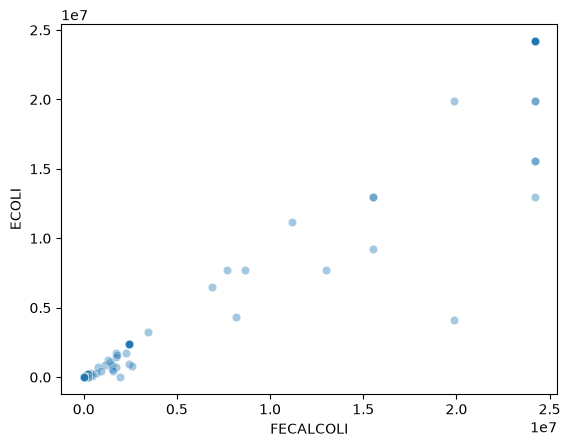

In [25]:
# Investigate relatinship between ECOLI and FECALCOLI
sns.scatterplot(
    data=df_pivot,
    x='FECALCOLI',
    y='ECOLI',
    alpha=0.4
)

plt.show()

### ^ Fecal Coliform and E.Coli Correlation
FECALCOLI and ECOLI show a strong positive relationship. Higher fecal coliform concentrations generally correspond to higher E. coli concentrations, although some observations deviate from this pattern.

### Investigating outliers in E.Coli column
* E. coli measurements reached 24,196,000.
* Extreme values had a '>' flag and Fair data quality, suggesting measurements exceeded a reporting limit rather than necessarily being errors.
* These observations were kept because extreme values alone do not establish invalid data.

In [26]:
# Inspect the highest E. coli measurements and their corresponding records
df_pivot.nlargest(10, 'ECOLI')[
    ['GEMS Station Number', 'Sample Date', 'Sample Time',
     'Depth', 'ECOLI']
]

,GEMS Station Number,Sample Date,Sample Time,Depth,ECOLI
674,MEX00213,2018-07-09,12:00,0.3,24196000.0
945,MEX00263,2019-01-23,12:00,0.3,24196000.0
980,MEX00264,2018-02-09,12:00,0.3,24196000.0
1117,MEX00272,2019-01-23,12:00,0.3,24196000.0
12600,MEX01318,2018-04-12,12:00,0.3,24196000.0
22498,MEX02192,2018-07-27,12:00,0.3,24196000.0
22499,MEX02192,2018-10-22,12:00,0.3,24196000.0
22500,MEX02192,2018-12-05,12:00,0.3,24196000.0
22501,MEX02192,2019-03-01,12:00,0.3,24196000.0
22502,MEX02192,2019-08-28,12:00,0.3,24196000.0


In [27]:
df_pivot['ECOLI'].describe(percentiles=[.90, .95, .99, .999])

count    4.646700e+04
mean     2.371018e+04
std      5.426786e+05
min      1.000000e+00
90%      2.400000e+04
95%      2.400000e+04
99%      2.419600e+04
99.9%    2.419600e+06
max      2.419600e+07
Name: ECOLI, dtype: float64

# 5. Data Cleaning
* There are 0 duplicated rows.
* Missing values in each column range from 239 to 6491 values. This is between 0.51% to 13.97% of missing values per columns. This will be handled using SimpleImputer() during preprocessing.
* There were 0 rows missing more than 75% of features.
* Index, gems station number, sample date, sample time were dropped from the dataset.
* According to the World Health Organization, E.coli measures of 100MPN/100mL or more is considered high or very high risk. Therefore, I established 100 as my baseline and samples less than 100 were 0 and samples greater than equal to 100 are 1.
* The class distibution of the target variable E.Coli was 0.617 positive and 0.383 negative.

In [28]:
df_pivot.shape

(46467, 25)

In [29]:
# Check for duplicates
df_pivot.duplicated().sum()

np.int64(0)

In [30]:
# Check for missing values
df_pivot.isnull().sum().sort_values()

index                     0
GEMS Station Number       0
Sample Date               0
Sample Time               0
Depth                     0
ECOLI                     0
FECALCOLI               239
TEMP                    371
TSS                     382
TDS                     416
TURB                    423
EC                      424
NO2N                    464
NO3N                    570
BOD                     577
TP                      605
TON                     659
NH3N                    716
TRP                     852
TOC                     902
pH                      984
COD                    1119
TN                     1286
O2-Dis                 1990
TKN                    6491
dtype: int64

In [31]:
# Drop columns missing more than 75% of features
df_pivot = df_pivot.dropna(thresh=int(df_pivot.shape[1] * 0.25))

In [32]:
df_pivot.shape

(46467, 25)

In [33]:
# Drop index, gems station number, sample date, sample time
df_pivot = df_pivot.drop(columns=['index', 'GEMS Station Number', 'Sample Date', 'Sample Time'])

In [34]:
# Check data types
df_pivot.dtypes

Depth        float64
BOD          float64
COD          float64
EC           float64
ECOLI        float64
FECALCOLI    float64
NH3N         float64
NO2N         float64
NO3N         float64
O2-Dis       float64
TDS          float64
TEMP         float64
TKN          float64
TN           float64
TOC          float64
TON          float64
TP           float64
TRP          float64
TSS          float64
TURB         float64
pH           float64
dtype: object

In [35]:
# Turn e.coli into classes. 0 = negative or 1 = positive
df_pivot["ECOLI"] = np.where(df_pivot["ECOLI"] < 100, 0, 1)

In [36]:
# Check if ECOLI is now correctly in classes
df_pivot["ECOLI"].unique()

array([1, 0])

In [37]:
# Check proportionality of target variable
df_pivot['ECOLI'].value_counts(normalize=True).round(3)

ECOLI
1    0.617
0    0.383
Name: proportion, dtype: float64

# 6. Model Building
* Missing feature entries are handled inside the pipeline using SimpleImputer(strategy='median'). The median is used to prevent extreme spikes from distorting the filled values.
* Features are standardized using RobustScaler(). This centers the data using the median and Interquartile Range (IQR), protecting the model from the outliers identified during exploratory data analysis (EDA).
* Max iterations was expanded to from max_iter=100 to max_iter=1000 to prevent early termination warnings and generate convergence.
* The three models created were a baseline model made with DummyClassifier() to find the majority class probability, a logistic regression model with FECALCOLI as a feature and a logistic regression model without FECALCOLI as a feature.

In [43]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [39]:
# Create x and y, then split data into 75% training and 25% testing sets.
X = df_pivot.drop(['ECOLI'], axis = 1)
y = df_pivot['ECOLI']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, stratify = y)

In [44]:
from sklearn.dummy import DummyClassifier

def build_pipe(columns):
    num_processor = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', RobustScaler())
    ])
    transformer = ColumnTransformer([('num_processing', num_processor, columns)])
    return Pipeline([
        ('transformer', transformer),
        ('lgr', LogisticRegression(max_iter=1000))
    ])

def evaluate(model, X_tr, X_te, name):
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba)
    }

results = []

# 1. Dummy baseline for majority values
dummy = DummyClassifier(strategy='most_frequent')
results.append(evaluate(dummy, X_train, X_test, 'Dummy (majority class)'))

# 2. Logistic regression WITH FECALCOLI 
results.append(evaluate(build_pipe(X_train.columns), X_train, X_test, 'LogReg + FECALCOLI'))

# 3. Logistic regression WITHOUT FECALCOLI
cols_no_fc = X_train.columns.drop('FECALCOLI')
results.append(evaluate(build_pipe(cols_no_fc), X_train[cols_no_fc], X_test[cols_no_fc], 'LogReg - FECALCOLI'))

results_df = pd.DataFrame(results).round(4)

# 7. Model Evaluation
### Results:
##### Key Performance Metrics:
* Accuracy: 0.7795 with FECALCOLI and 0.7078 without it. Removing FECALCOLI reduced accuracy by 7.17 percentage points.
* Precision: 0.8325 with FECALCOLI and 0.6989 without it. Without FECALCOLI, more positive predictions were false alarms.
* Recall: 0.8047 with FECALCOLI and 0.9248 without it. Removing FECALCOLI increased recall, allowing the model to identify more contaminated samples.
* F1-Score: 0.8184 with FECALCOLI and 0.7962 without it. The model with FECALCOLI achieved a better balance between precision and recall.
* ROC-AUC: 0.8612 with FECALCOLI and 0.7527 without it. FECALCOLI improved the model's ability to distinguish between positive and negative samples.
* The dummy baseline achieved 0.6171 accuracy and 0.5000 ROC-AUC, confirming that both logistic regression models performed better than a majority-class prediction baseline.

##### Key Feature Drivers (without FECALCOLI):
* Negative coefficients: Depth was the strongest negative coefficient at -8.2285, followed by O2-Dis at -0.3870 and pH at -0.1926, indicating lower predicted odds of E. coli presence as these features increased.

* Positive coefficients: TP had the strongest positive coefficient at 0.0820, followed by TDS and TN at 0.0706 each, indicating higher predicted odds of E. coli presence as these features increased.

In [45]:
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (majority class),0.6171,0.6171,1.0000,0.7632,0.5000
1,LogReg + FECALCOLI,0.7795,0.8325,0.8047,0.8184,0.8612
2,LogReg - FECALCOLI,0.7078,0.6989,0.9248,0.7962,0.7527


In [46]:
# Features and coefficients without FECALCOLI

model_no_fc = build_pipe(cols_no_fc)
model_no_fc.fit(X_train[cols_no_fc], y_train)

coef_df = pd.DataFrame({
    'Feature': cols_no_fc,
    'Coefficient': model_no_fc.named_steps['lgr'].coef_[0]
})

coef_df = coef_df.reindex(
    coef_df['Coefficient'].abs().sort_values(ascending=False).index
).reset_index(drop=True)

coef_df.round(4).sort_values(by='Coefficient')

,Feature,Coefficient
0,Depth,-8.2285
1,O2-Dis,-0.3870
2,pH,-0.1926
3,EC,-0.1124
5,TEMP,-0.0733
11,TON,-0.0174
12,TRP,-0.0173
14,TOC,-0.0092
18,NO2N,0.0008
17,COD,0.0033


# 8. Conclusion

FECALCOLI substantially improved overall model performance, increasing accuracy from 70.78% to 77.95% and ROC-AUC from 0.7527 to 0.8612. However, the model without FECALCOLI achieved higher recall (92.48% versus 80.47%), making it potentially useful when missing contaminated samples is the primary concern.

For routine water-quality monitoring, the model without FECALCOLI is particularly relevant because it evaluates whether other water-quality measurements can help identify potential E. coli contamination without relying on a closely related fecal indicator. Its lower precision means that more false alarms should be expected. Further validation on independent samples is needed before using either model for operational water-quality decisions.

